In [1]:
# Load the data and compute brands 

%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import pandas as pd
from src.evaluation import brand_of, split_by_brand

df = pd.read_csv("../data/processed/transactions_clean.csv")
df["brand"] = df["merchant"].apply(brand_of)

print(f"{df['merchant'].nunique()} merchants -> {df['brand'].nunique()} brands")

586 merchants -> 519 brands


In [2]:
# Which merchants were grouped together ? 

merchants_per_brand = df.groupby("brand")["merchant"].unique()
multi = merchants_per_brand[merchants_per_brand.apply(len) > 1]

for brand, merchants in multi.items():
    print(f"{brand:<14}{', '.join(merchants)}")

ALLIANZ       ALLIANZ, ALLIANZ FRANCE
AMAZON        AMAZON PRIME, AMAZON, AMAZON MKTPLACE
APPLE         APPLE MUSIC, APPLE.COM/BILL, APPLE STORE
AXA           AXA, AXA FRANCE, AXA SANTE, AXA BANQUE
BOUYGUES      BOUYGUES BOX, BOUYGUES TELECOM, BOUYGUES
BRIAND        BRIAND ARTHUR, BRIAND ZACHARIE
CAF           CAF DE L ESSONNE, CAF DU RHONE, CAF DU NORD, CAF DE LYON, CAF DES HAUTS DE SEINE, CAF DE LA LOIRE, CAF DE MARSEILLE, CAF DE PARIS, CAF
CARREFOUR     CARREFOUR CITY, CARREFOUR MARKET, CARREFOUR
CARSAT        CARSAT AQUITAINE, CARSAT SUD EST, CARSAT NORD PICARDIE, CARSAT, CARSAT BRETAGNE
CASINO        CASINO PROXIMITE, CASINO SHOP
CHEVALIER     CHEVALIER DOMINIQUE, CHEVALIER FRANCOISE
CITYA         CITYA, CITYA IMMOBILIER
CPAM          CPAM PARIS, CPAM DU RHONE, CPAM DES BOUCHES DU RHONE, CPAM DE LA GIRONDE, CPAM ILE DE FRANCE, CPAM
DGFIP         DGFIP TAXE FONCIERE, DGFIP REMBOURSEMENT IMPOT
DOCTOLIB      DOCTOLIB, DOCTOLIB*DR LEROY
FNAC          FNAC, FNAC SPECTACLES
FRANPRIX    

In [3]:
# Split and check 

train, test = split_by_brand(df)

shared = set(train["brand"]) & set(test["brand"])
print(f"Train: {len(train)} rows | Test: {len(test)} rows ({len(test) / len(df):.0%})")
print(f"Brands present in both sets: {len(shared)}\n")

pd.DataFrame({
    "train": train["category"].value_counts(),
    "test": test["category"].value_counts(),
})

Train: 3969 rows | Test: 991 rows (20%)
Brands present in both sets: 0



,train,test
category,,
Bank Fees,251,62
Cash Withdrawal,397,102
Groceries,397,102
Health,365,88
Housing & Utilities,274,69
Income,214,53
Leisure & Travel,363,92
Restaurants,401,98
Shopping,400,100


In [4]:
# Build and train the pipeline 

from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), token_pattern=r"(?u)\b\w+\b"),
    LogisticRegression(max_iter=1000),
)
baseline.fit(train["clean_label"], train["category"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](12,)","['Bank Fees','Cash Withdrawal','Groceries',...,'Subscriptions','Transfers', 'Transport']"
,"token_pattern token_pattern: str, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp selects tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'(?u)\\b\\w+\\b'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


In [5]:
# What does YF-IDF see ? 

vectorizer = baseline.named_steps["tfidfvectorizer"]
vocabulary = vectorizer.get_feature_names_out()
print(f"Vocabulary size: {len(vocabulary)}\n")

example = vectorizer.transform(["CB CARREFOUR MARKET PARIS"])
for index in example.nonzero()[1]:
    print(f"{vocabulary[index]:<22}{example[0, index]:.3f}")

Vocabulary size: 3161

carrefour             0.348
carrefour market      0.424
cb                    0.130
cb carrefour          0.417
market                0.424
market paris          0.506
paris                 0.268


In [6]:
# Evaluate on the synthetic test set 

from sklearn.metrics import classification_report
from src.evaluation import evaluate

test_pred = baseline.predict(test["clean_label"])

evaluate(test["category"], test_pred, "Baseline (synthetic test)")
print()
print(classification_report(test["category"], test_pred, digits=3))

Baseline (synthetic test)        accuracy: 52.7% | macro F1: 53.7%

                     precision    recall  f1-score   support

          Bank Fees      1.000     0.839     0.912        62
    Cash Withdrawal      1.000     1.000     1.000       102
          Groceries      0.482     0.392     0.432       102
             Health      0.945     0.591     0.727        88
Housing & Utilities      0.350     0.710     0.469        69
             Income      0.671     1.000     0.803        53
   Leisure & Travel      0.660     0.337     0.446        92
        Restaurants      0.406     0.133     0.200        98
           Shopping      0.236     0.750     0.359       100
      Subscriptions      0.810     0.191     0.309        89
          Transfers      0.500     0.435     0.465        46
          Transport      0.818     0.200     0.321        90

           accuracy                          0.527       991
          macro avg      0.656     0.548     0.537       991
       weighted

In [7]:
# What if we had split randomly ? 

from sklearn.base import clone
from sklearn.model_selection import train_test_split

random_train, random_test = train_test_split(
    df, test_size=0.2, stratify=df["category"], random_state=42
)
random_model = clone(baseline).fit(random_train["clean_label"], random_train["category"])
random_pred = random_model.predict(random_test["clean_label"])

evaluate(random_test["category"], random_pred, "Baseline (random split)")

shared = set(random_train["brand"]) & set(random_test["brand"])
print(f"Brands present in both sets: {len(shared)}")

Baseline (random split)          accuracy: 98.0% | macro F1: 98.2%
Brands present in both sets: 416


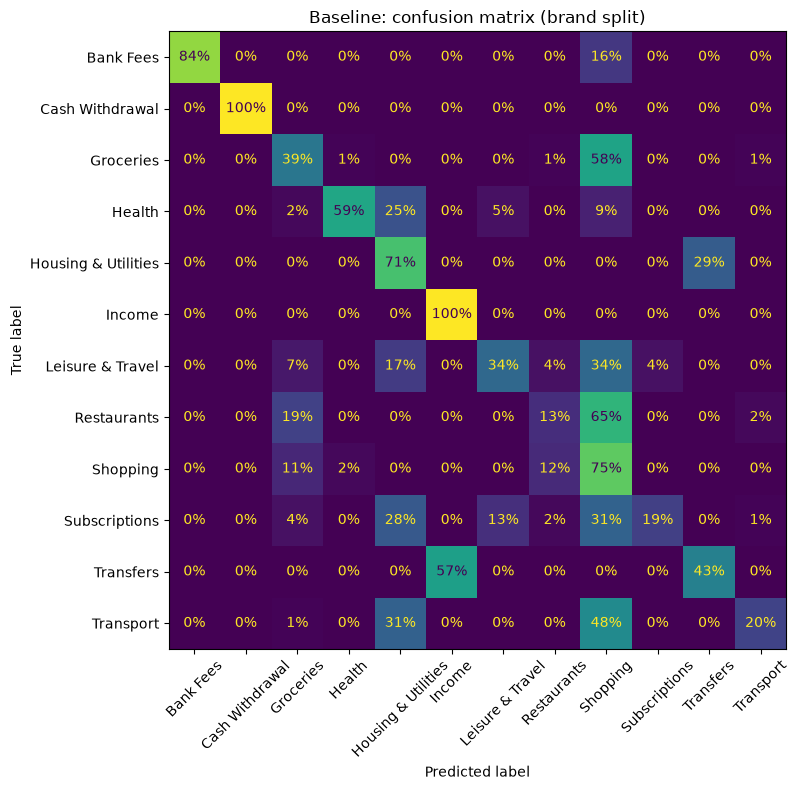

In [8]:
# The confusion matrix 

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    test["category"],
    test_pred,
    normalize="true",
    values_format=".0%",
    xticks_rotation=45,
    colorbar=False,
    ax=ax,
)
ax.set_title("Baseline: confusion matrix (brand split)")
plt.tight_layout()
plt.show()

In [9]:
# The baseline on the realistic set 

from src.preprocessing import clean_label

realistic = pd.read_csv("../data/test_realistic.csv")
realistic["clean_label"] = realistic["label"].apply(clean_label)

full_model = clone(baseline).fit(df["clean_label"], df["category"])

realistic["predicted"] = full_model.predict(realistic["clean_label"])
realistic["confidence"] = full_model.predict_proba(realistic["clean_label"]).max(axis=1)

evaluate(realistic["category"], realistic["predicted"], "Baseline (realistic set)")

errors = realistic[realistic["predicted"] != realistic["category"]]
print(f"\n{len(errors)} errors out of {len(realistic)}\n")
errors[["clean_label", "category", "predicted", "confidence"]].sort_values("confidence")

Baseline (realistic set)         accuracy: 73.3% | macro F1: 73.4%

16 errors out of 60



,clean_label,category,predicted,confidence
14,FACTURE CARTE DU Q PARK FRANCE CARTE 4974XXXXX...,Transport,Restaurants,0.202630
33,FACTURE CARTE DU OPTIC CARTE 4974XXXXXXXX1234,Health,Shopping,0.247166
6,FACTURE CARTE DU PRET A MANGER CARTE 4974XXXXX...,Restaurants,Shopping,0.257466
3,PAIEMENT CB ROUEN MONOP,Groceries,Shopping,0.259956
0,CARTE BIOCBON PARIS 11,Groceries,Shopping,0.261266
12,PRLV SEPA BIP GO ECH,Transport,Housing & Utilities,0.354257
35,CB CINEMA LE BALZAC,Leisure & Travel,Subscriptions,0.358914
37,PRLV SEPA L ORANGE BLEUE,Leisure & Travel,Subscriptions,0.408083
19,CB DASHLANE,Subscriptions,Shopping,0.516752
13,CB FREENOW,Transport,Shopping,0.516752
